# Fourteen arms through ten folds: what each one scores and where each one refuses

**Level 2: The method in practice** · Needs: 05-learned-arms/01-fitting-a-learned-arm-on-nine-sites · Reading time: about 35 minutes

## Objectives

The product's benchmark has fourteen arms: two controls, the classical family, the statistical ones and the learned tier. Each answers a blast with a number or with a stated refusal, and a refusal is a result, never averaged away. This notebook runs the whole ladder through the ten site-held-out folds and reads both the scores and the refusals.

By the end you will have:

- run all fourteen arms through leave-one-site-out and reproduced the committed pooled score of every one;
- listed every refusal with its reason and the campaign it came from, and understood why each arm refuses where it does;
- compared the arms on the same blasts only, which is the fair way to rank arms that answer different numbers of rows.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 blasts | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The fourteen arms as published | Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3; Sui et al. 2025, https://doi.org/10.3390/app15031254; and the papers cited in topic 02 | the methods are cited, the engine implements them | `bf.default_arms()` |
| The committed pooled scores and the common-rows scores | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/benchmark.json`, field `protocols` |

## Method

An arm refuses for one of three reasons, and each is declared in the engine rather than hidden:

1. **It cannot know the input it needs.** The classical family needs a rock volume and a charge, which a site with no published hole diameter cannot supply (Miami).
2. **It is not a size predictor.** The group discriminant assigns a rock-stiffness group; it abstains on size for every blast by design.
3. **Its output leaves the physical range.** A model that returns a mean size outside the plausible fragment range, 1 mm to a couple of metres, has left its domain, and the engine refuses the number instead of scoring it. Holding out one site and refitting the published power law once extrapolated to 10.48 m, which scored as a variance explained of -11355 for that fold and swamped the pooled figure.

Because the arms answer different numbers of rows, a pooled score over each arm's own rows compares different denominators. The engine therefore also reports each arm's score on the rows every size-predicting arm answers, the common rows, beside its own and never as the verdict.

### Step 1: run the ladder through the ten folds

For each of the fourteen arms the cell builds a fresh instance per fold with `fit(training)`, predicts the held-out site and pools the out-of-fold predictions. The whole run takes under a minute. The classical arms and the controls ignore `fit`, as the base class allows.

In [2]:
# Imports, then the fourteen arms through leave-one-site-out
import json
import re
from collections import Counter
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
loso = benchmark["protocols"]["leave-one-site-out"]["arms"]
factories = bf.default_arms()
folds = list(bf.leave_one_site_out(train))
tested = [b for fold in folds for b in fold.test]
predictions = {}
for name, make in factories.items():
    out = []
    for fold in folds:
        out += make().fit(fold.train).predict(fold.test)
    predictions[name] = out
print("arms:", len(predictions), "| out-of-fold blasts per arm:", len(tested))

arms: 14 | out-of-fold blasts per arm: 97


### Step 2: the pooled score of every arm, beside the committed one

The cell scores each arm's answered rows and compares with the committed pooled `r2_identity`. It also prints the committed score on the common rows, the blasts every size-predicting arm answered.

In [3]:
# Pooled r2_identity per arm, whether it equals the committed value, and the committed score on the common rows
print(f"{'arm':<22}{'tier':<18}{'answered':>9}{'refused':>9}{'r2 identity':>14}  {'committed':<10}{'common rows':>14}")
scores = {}
for name, preds in predictions.items():
    s = bf.score(tested, preds, method=name)
    scores[name] = s
    want = loso[name]["r2_identity"]
    same = (s.r2_identity is None and want is None) or (s.r2_identity is not None and want is not None and abs(s.r2_identity - want) < 1e-9)
    common = loso[name]["common"]["score"]["r2_identity"] if "common" in loso[name] else None
    value = f"{s.r2_identity:.3f}" if s.r2_identity is not None else "-"
    common_text = f"{common:.3f}" if common is not None else "-"
    print(f"{name:<22}{loso[name]['tier']:<18}{s.n_scored:>9}{s.n_abstained:>9}{value:>14}  {str(same):<10}{common_text:>14}")

arm                   tier               answered  refused   r2 identity  committed    common rows
null                  control                  97        0        -0.216  True              -0.229
oracle                control                  97        0         1.000  True               1.000
kuznetsov             classical                91        6         0.311  True               0.318
kuznetsov-transfer    classical                91        6         0.298  True               0.293
kuznetsov-capped      classical                91        6         0.352  True               0.364
group-discriminant    statistical               0       97             -  True                   -
published-regression  statistical              97        0         0.802  True               0.766
refitted-regression   statistical              93        4        -4.075  True              -3.715
published-neural-net  learned                  97        0        -0.626  True              -0.491
svr-rbf   

### Step 3: every refusal, with its reason

A refusal carries the engine's reason as text. The cell groups the refusals of each arm by reason (replacing the numbers inside the text by `#` so that equal reasons count together) and by the campaign they came from.

In [4]:
# Group the refusals of each arm by reason and by campaign
for name, preds in predictions.items():
    refused = [(b, p) for b, p in zip(tested, preds) if p.abstained]
    if not refused:
        continue
    reasons = Counter(re.sub(r"[-+]?\d+\.?\d*(e[-+]?\d+)?", "#", p.abstain_reason) for _, p in refused)
    sites = Counter(b.site for b, _ in refused)
    print(f"{name} ({len(refused)} refusals) from: {dict(sites)}")
    for reason, count in reasons.items():
        print(f"    {count:>3} x {reason[:118]}")

kuznetsov (6 refusals) from: {'Miami': 6}
      6 x Miami publishes no hole diameter, so rock volume and charge mass cannot be resolved; this equation needs both
kuznetsov-transfer (6 refusals) from: {'Miami': 6}
      6 x Miami publishes no hole diameter, so rock volume and charge mass cannot be resolved; this equation needs both
kuznetsov-capped (6 refusals) from: {'Miami': 6}
      6 x Miami publishes no hole diameter, so rock volume and charge mass cannot be resolved; this equation needs both
group-discriminant (97 refusals) from: {'Akdaglar': 22, 'Dongri-Buzurg': 9, 'Enusa': 12, 'Miami': 6, 'Mrica': 11, 'Murgul': 7, 'Ozmert': 7, 'Reocin': 10, 'Reocin-UG': 6, 'Soma': 7}
     97 x this arm assigns a rock-stiffness group rather than a fragment size
refitted-regression (4 refusals) from: {'Murgul': 4}
      4 x the model returned # m, which is outside the plausible fragment range # to # m. This is the model leaving its domain, 
svr-rbf (1 refusals) from: {'Akdaglar': 1}
      1 x the 

### Step 4: the fair ranking

The cell draws the pooled score of each scored arm and its score on the common rows (the 79 blasts, from nine campaigns, that all size-predicting arms answered). The arms that refuse more are scored on fewer, different rows in the first bar; in the second bar they all face the same ones.

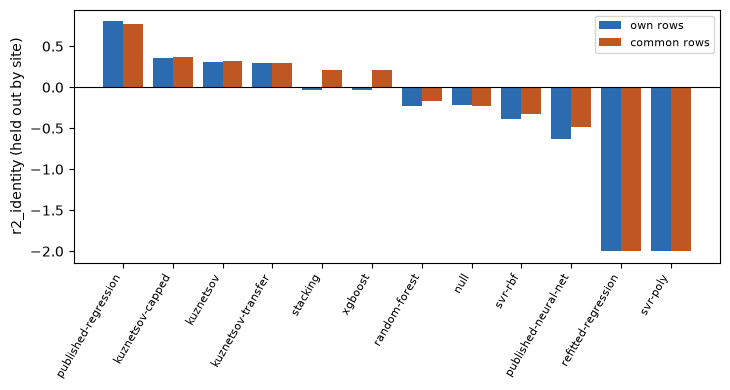

In [5]:
# Pooled score against common-rows score per arm, clipped at -2 for legibility
ranked = [(n, scores[n].r2_identity, loso[n]["common"]["score"]["r2_identity"]) for n in scores
          if scores[n].r2_identity is not None and "common" in loso[n] and n not in ("oracle",)]
ranked.sort(key=lambda r: -r[2])
fig, ax = plt.subplots(figsize=(7.4, 4))
x = np.arange(len(ranked))
ax.bar(x - 0.2, [max(r[1], -2) for r in ranked], 0.4, color="#2b6cb0", label="own rows")
ax.bar(x + 0.2, [max(r[2], -2) for r in ranked], 0.4, color="#c05621", label="common rows")
ax.set_xticks(x, [r[0] for r in ranked], rotation=60, ha="right", fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("r2_identity (held out by site)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

**The pooled scores reproduce the committed benchmark for all fourteen arms.** The oracle scores a perfect 1, the published regression a high value that is an in-sample fit (its source fitted it on these blasts), and the null a clearly negative one. The classical equation and its two variants score around 0.3; gradient boosting and stacking sit just below zero; the rest of the learned arms are further below.

**Every refusal has a reason and a place.** The classical family refuses the six Miami blasts, whose scale is not published. The group discriminant refuses all 97 because it predicts a group. The only refusals of the learned and refitted arms are of the third kind: the refitted power law refuses four Murgul blasts, the radial support vector regressor one Akdaglar blast and the polynomial one eleven blasts from four campaigns, because the model returned a size outside the plausible range. These are not failures to compute; they are the engine declining to score arithmetic.

**Pooled scores over different rows are not a ranking.** The polynomial support vector regressor is scored on 86 blasts and the classical family on 91, so the first bar mixes different denominators. On the common rows every size-predicting arm faces the same 79 blasts, which leave out Miami and every blast an arm refused. There the level changes: gradient boosting and stacking score about +0.2 instead of about -0.03, because the finest campaign, where tree models make some of their largest errors, is no longer in the denominator, while the classical arms stay near 0.3 and the learned ones keep nearly the same order. The common-rows score is reported beside the arm's own and never decides the verdict, because the rows are chosen by the arms' own refusals.

**What this does not show.** An arm that refuses on a hard row looks better on the rows it answers. The refusals are therefore counted in the table, not only the score, and the product's verdict does not rank arms by the common-rows score.

## Summary

- All fourteen arms run through the ten folds, and the pooled scores equal the committed benchmark.
- A refusal is one of three kinds: an input that cannot be known, an arm that is not a size predictor, or an output outside the physical range.
- Rank arms on the same rows, and report the refusals beside every score.
- Next: notebook 03 reproduces the published neural network and shows how unstable its published score is (level 3).

## References

- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the network and the regression)
- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (forest, boosting, stacking, polynomial support vector)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus and the published regression)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/